# Thermal equilibrium

Uniform gas and radiation out of equilibrium relax to a common temperature at constant total
energy (Jiang 2021, ApJS 253, 49, sec. 4.1; `decks/thermal_eq.athinput`). The exact solution is
the ODE $de/dt = c\,\kappa_P \rho\,(E - a_r T^4)$, $e = \rho T/(\gamma-1)$, $e + E$ = const
(`vett.relax_ode`). Two time steps, $2.5\times10^{-7}$ and $1.25\times10^{-7}$ (the relaxation
time is ~3e-6). Criterion: error of $T$ at the small step $\le 2\times10^{-4}$, order $\ge 1.8$,
total energy conserved to $10^{-13}$.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TEST = 'thermal_eq'
res = nb.suite(TEST, EXE, WORK, THREADS)

loading the existing run runs/thermal_eq


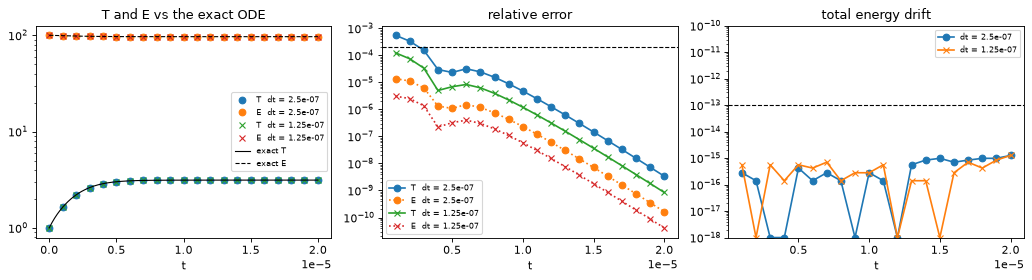

In [3]:
vett = nb.vett
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for tag, mk in (('h', 'o'), ('h2', 'x')):
    d = os.path.join(WORK, TEST, 'dt' + tag)
    p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
    cl, ka, ar = (float(p['rad_vet'][k]) for k in ('c_light', 'kappa_p', 'arad'))
    rho, gm1 = float(p['problem']['gas_rho']), float(p['hydro']['gamma']) - 1.0
    T0, E0 = float(p['problem']['gas_eint'])*gm1/rho, float(p['problem']['e_rad'])
    tot = rho*T0/gm1 + E0
    t, T, E = [], [], []
    for fm, fh in zip(vett.bins(d, 'vet'), vett.bins(d, 'hydro_w')):
        m, h = vett.read_bin(fm), vett.read_bin(fh)
        t.append(m['time']); E.append(m['vet_e'].mean()); T.append((h['eint']*gm1/h['dens']).mean())
    t, T, E = map(np.array, (t, T, E))
    Tex = np.array([vett.relax_ode(T0, tot, rho, gm1, cl*ka*rho, x, arad=ar) for x in t])
    Eex = tot - rho*Tex/gm1
    lab = 'dt = %s' % p['time']['dt_fixed']
    axs[0].plot(t, T, mk, label='T  ' + lab); axs[0].plot(t, E, mk, label='E  ' + lab)
    axs[1].semilogy(t[1:], abs(T[1:]/Tex[1:] - 1), mk + '-', label='T  ' + lab)
    axs[1].semilogy(t[1:], abs(E[1:]/Eex[1:] - 1), mk + ':', label='E  ' + lab)
    axs[2].semilogy(t[1:], np.maximum(abs(E + rho*T/gm1 - tot)[1:]/tot, 1e-18), mk + '-', label=lab)
tt = np.linspace(0, t[-1], 200)
Tl = np.array([vett.relax_ode(T0, tot, rho, gm1, cl*ka*rho, x, arad=ar, nstep=2000) for x in tt])
axs[0].plot(tt, Tl, 'k-', lw=1, label='exact T'); axs[0].plot(tt, tot - rho*Tl/gm1, 'k--', lw=1, label='exact E')
axs[0].set(xlabel='t', yscale='log', title='T and E vs the exact ODE'); axs[0].legend(fontsize=7)
axs[1].axhline(2e-4, c='k', ls='--', lw=1); axs[1].set(xlabel='t', title='relative error'); axs[1].legend(fontsize=7)
axs[2].axhline(1e-13, c='k', ls='--', lw=1); axs[2].set(xlabel='t', title='total energy drift', ylim=(1e-18, 1e-10))
axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [4]:
print({k: v for k, v in res.items() if k != 'wall'})
_ = nb.verdict(TEST, res)

{'errT_h': 0.0005520270555068318, 'dEtot_h': 1.2600757875548575e-15, 'errT_h2': 0.00012377200089186413, 'dEtot_h2': 1.2600757875548575e-15, 'order': 2.157053985036462}
PASS thermal_eq   criterion {"min": {"order": 1.8}, "max": {"errT_h2": 0.0002, "dEtot_h": 1e-13, "dEtot_h2": 1e-13}}
